In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)

# Caminho para os dados brutos
DATA_PATH = os.path.join("..", "data", "raw", "dados_sensores_aeromotion.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = r"C:\Users\henrique_schorck\Documents\GitHub\Projeto-Integrador-Aero\Machine-Learning\Arquivo_CSV\dados_sensores_aeromotion.csv"

df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset carregado com sucesso: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")
df_raw.head()

Dataset carregado com sucesso: 12000 linhas e 11 colunas.


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha
0,2026-01-01 00:00:00,TURB-103,Carga_Media,100.2,59.79,9.98,4.41,3006.8,48.96,39.68,2
1,2026-01-01 00:10:00,TURB-104,Carga_Alta,100.5,79.49,3.13,4.50,3487.9,59.76,40.02,0
2,2026-01-01 00:20:00,TURB-101,Cruzeiro,100.6,57.83,NaN,3.51,2382.7,44.97,18.73,0
3,2026-01-01 00:30:00,TURB-103,Carga_Media,100.9,64.56,1.43,4.15,3019.9,53.05,27.36,0
4,2026-01-01 00:40:00,TURB-103,Carga_Alta,101.1,70.80,3.44,4.91,3546.0,63.66,39.36,0


In [35]:
df_inspec = df_raw.copy()
df_inspec['timestamp'] = pd.to_datetime(df_inspec['timestamp'])
df_inspec = df_inspec.sort_values(by=['id_equipamento', 'timestamp']).reset_index(drop=True)

print("--- Tipos de Dados ---")
print(df_inspec.dtypes)

print("\n--- Verificação de Frequência Temporal por Bancada (Amostragem esperada: 10 min) ---")
for eq in sorted(df_inspec['id_equipamento'].unique()):
    sub = df_inspec[df_inspec['id_equipamento'] == eq]
    deltas = sub['timestamp'].diff().value_counts(normalize=True).head(3) * 100
    print(f"\nEquipamento {eq} (Total: {len(sub)} leituras):")
    print(deltas.to_string())

print("\n--- Taxa de Ausência de Dados (NaNs em %) Agrupada por Equipamento ---")
taxa_ausentes = (df_inspec.groupby('id_equipamento').apply(lambda g: g.isnull().mean()) * 100).round(2)
taxa_ausentes = taxa_ausentes[['temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'emissao_acustica_db']]
display(taxa_ausentes)

--- Tipos de Dados ---
timestamp                    datetime64[us]
id_equipamento                          str
modo_operacao                           str
horas_operacao_acumuladas           float64
temperatura_mancal_c                float64
vibracao_rms_mms                    float64
pressao_oleo_bar                    float64
rotacao_rpm                         float64
emissao_acustica_db                 float64
corrente_eletrica_amp               float64
tipo_falha                            int64
dtype: object

--- Verificação de Frequência Temporal por Bancada (Amostragem esperada: 10 min) ---

Equipamento TURB-101 (Total: 3043 leituras):
timestamp
0 days 00:10:00    25.443787
0 days 00:20:00    19.559500
0 days 00:30:00    14.266930

Equipamento TURB-102 (Total: 3021 leituras):
timestamp
0 days 00:10:00    25.099338
0 days 00:20:00    19.536424
0 days 00:30:00    13.509934

Equipamento TURB-103 (Total: 2965 leituras):
timestamp
0 days 00:10:00    24.595142
0 days 00:20:00    19.

,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,emissao_acustica_db
id_equipamento,,,,
TURB-101,2.79,2.99,2.76,4.01
TURB-102,3.51,2.75,2.65,4.44
TURB-103,3.78,3.20,2.87,4.05
TURB-104,3.57,2.79,2.66,3.64


In [36]:
df_clean = df_inspec.copy()

qtd_outliers_temp = (df_clean['temperatura_mancal_c'] > 150.0).sum()
qtd_outliers_vib = (df_clean['vibracao_rms_mms'] < 0.0).sum()

print(f"Ruídos EMI detectados: {qtd_outliers_temp} leituras de temperatura extrema (>150°C)")
print(f"Ruídos EMI detectados: {qtd_outliers_vib} leituras de vibração negativa (<0.0 mm/s)")

# Substituição por NaN para posterior interpolação contínua
df_clean.loc[df_clean['temperatura_mancal_c'] > 150.0, 'temperatura_mancal_c'] = np.nan
df_clean.loc[df_clean['vibracao_rms_mms'] < 0.0, 'vibracao_rms_mms'] = np.nan

Ruídos EMI detectados: 58 leituras de temperatura extrema (>150°C)
Ruídos EMI detectados: 45 leituras de vibração negativa (<0.0 mm/s)


In [37]:
colunas_continuas = [
    'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 
    'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp'
]

# Interpolação linear respeitando a física contínua de cada bancada isoladamente
df_interpolado = []
for eq, sub in df_clean.groupby('id_equipamento', as_index=False):
    sub = sub.sort_values('timestamp')
    sub[colunas_continuas] = sub[colunas_continuas].interpolate(method='linear')
    sub[colunas_continuas] = sub[colunas_continuas].bfill().ffill()
    df_interpolado.append(sub)

df_clean = pd.concat(df_interpolado, ignore_index=True)
print("Valores ausentes restantes após saneamento:")
print(df_clean.isnull().sum())

Valores ausentes restantes após saneamento:
timestamp                    0
id_equipamento               0
modo_operacao                0
horas_operacao_acumuladas    0
temperatura_mancal_c         0
vibracao_rms_mms             0
pressao_oleo_bar             0
rotacao_rpm                  0
emissao_acustica_db          0
corrente_eletrica_amp        0
tipo_falha                   0
dtype: int64


In [38]:
df_features_list = []

for eq, sub in df_clean.groupby('id_equipamento', as_index=False):
    sub = sub.sort_values('timestamp').set_index('timestamp')
    
    # Janela de 1 hora
    sub['vibracao_mean_1h'] = sub['vibracao_rms_mms'].rolling('1h', min_periods=1).mean()
    sub['vibracao_std_1h'] = sub['vibracao_rms_mms'].rolling('1h', min_periods=1).std().fillna(0)
    sub['temp_mean_1h'] = sub['temperatura_mancal_c'].rolling('1h', min_periods=1).mean()
    sub['temp_std_1h'] = sub['temperatura_mancal_c'].rolling('1h', min_periods=1).std().fillna(0)
    
    # Janela de 6 horas
    sub['vibracao_mean_6h'] = sub['vibracao_rms_mms'].rolling('6h', min_periods=1).mean()
    sub['vibracao_std_6h'] = sub['vibracao_rms_mms'].rolling('6h', min_periods=1).std().fillna(0)
    sub['temp_mean_6h'] = sub['temperatura_mancal_c'].rolling('6h', min_periods=1).mean()
    sub['temp_std_6h'] = sub['temperatura_mancal_c'].rolling('6h', min_periods=1).std().fillna(0)
    
    # Feature Derivada: Severidade Dinâmica (Vibração RMS / Rotação RPM)
    sub['severidade_dinamica'] = sub['vibracao_rms_mms'] / sub['rotacao_rpm']
    
    sub = sub.reset_index()
    df_features_list.append(sub)

df_final = pd.concat(df_features_list, ignore_index=True)
df_final = df_final.sort_values(by=['timestamp', 'id_equipamento']).reset_index(drop=True)
print(f"Features calculadas com sucesso! Formato final: {df_final.shape}")
df_final[['timestamp', 'id_equipamento', 'vibracao_mean_1h', 'severidade_dinamica']].head()

Features calculadas com sucesso! Formato final: (12000, 20)


,timestamp,id_equipamento,vibracao_mean_1h,severidade_dinamica
0,2026-01-01 00:00:00,TURB-103,9.980,0.003319
1,2026-01-01 00:10:00,TURB-104,3.130,0.000897
2,2026-01-01 00:20:00,TURB-101,2.500,0.001049
3,2026-01-01 00:30:00,TURB-103,5.705,0.000474
4,2026-01-01 00:40:00,TURB-103,4.950,0.000970


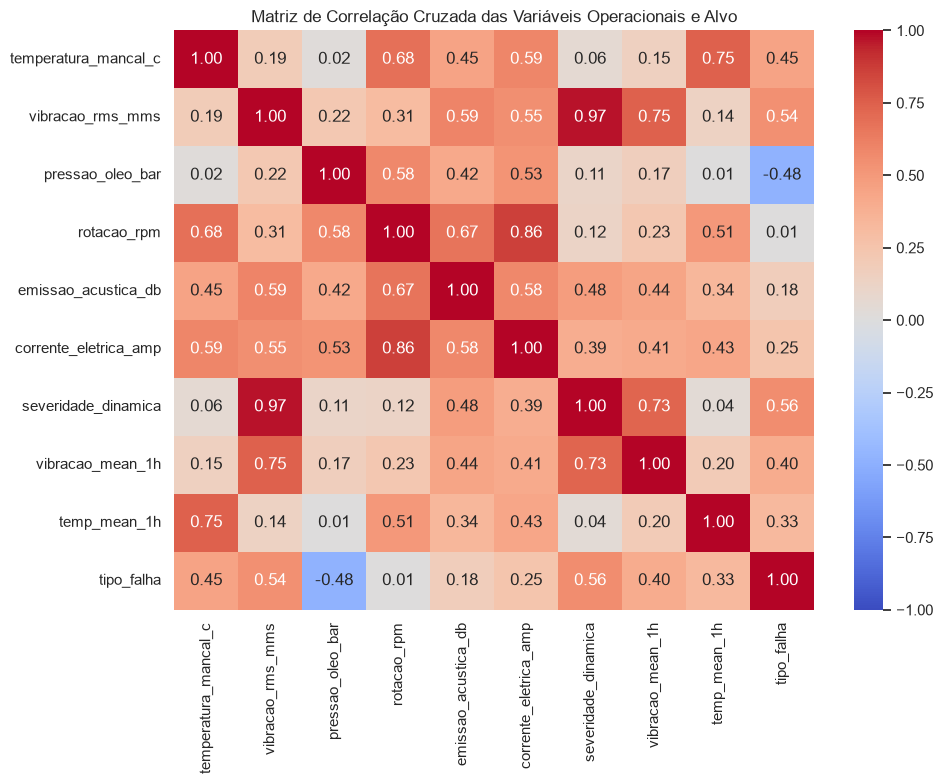

In [39]:
features_analise = [
    'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 
    'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp',
    'severidade_dinamica', 'vibracao_mean_1h', 'temp_mean_1h', 'tipo_falha'
]

plt.figure(figsize=(10, 8))
corr = df_final[features_analise].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=True)
plt.title("Matriz de Correlação Cruzada das Variáveis Operacionais e Alvo")
plt.tight_layout()
plt.show()

C:\Users\henrique_schorck\AppData\Local\Temp\ipykernel_23896\742167119.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_final, x='modo_operacao', y='rotacao_rpm', ax=axes[0], palette="Blues_d")
C:\Users\henrique_schorck\AppData\Local\Temp\ipykernel_23896\742167119.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_final, x='modo_operacao', y='temperatura_mancal_c', ax=axes[1], palette="Reds_d")
C:\Users\henrique_schorck\AppData\Local\Temp\ipykernel_23896\742167119.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d

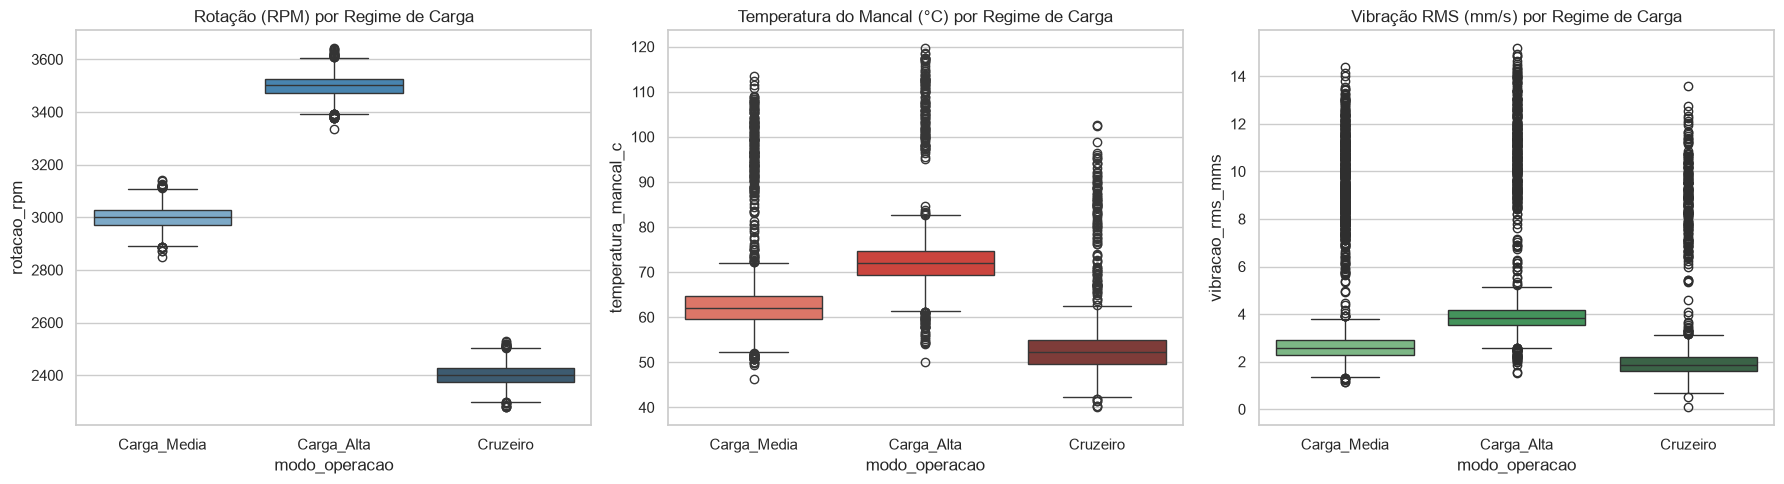

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df_final, x='modo_operacao', y='rotacao_rpm', ax=axes[0], palette="Blues_d")
axes[0].set_title("Rotação (RPM) por Regime de Carga")

sns.boxplot(data=df_final, x='modo_operacao', y='temperatura_mancal_c', ax=axes[1], palette="Reds_d")
axes[1].set_title("Temperatura do Mancal (°C) por Regime de Carga")

sns.boxplot(data=df_final, x='modo_operacao', y='vibracao_rms_mms', ax=axes[2], palette="Greens_d")
axes[2].set_title("Vibração RMS (mm/s) por Regime de Carga")
plt.tight_layout()
plt.show()

In [41]:
PROCESSED_DIR = os.path.join("..", "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)
OUTPUT_FILE = os.path.join(PROCESSED_DIR, "dados_sensores_tratados.csv")
df_final.to_csv(OUTPUT_FILE, index=False)
print(f"Dataset exportado com sucesso para: {OUTPUT_FILE}")

Dataset exportado com sucesso para: ..\data\processed\dados_sensores_tratados.csv
